In [1]:
print("[+] Installing Package Dependencies...")

!uv add \
  "numpy" \
  "pandas" \
  "matplotlib" \
  "torch" \
  "torchvision" \
  "brevitas" \
  "optuna" \
  "hls4ml[da,onnx,profiling]" \
  "onnx" \
  "qonnx" \
  "onnxoptimizer"

print("[+] Package Dependencies successfully installed!")

[+] Installing Package Dependencies...
Resolved 110 packages in 10ms
Checked 106 packages in 27ms
[+] Package Dependencies successfully installed!


In [57]:
import os
import random
import torch
import numpy


print("[+] Setting up Environment...")

# Define Seed
SEED = 42

# Manually Seed Everything for Reproducibility
random.seed(SEED)
numpy.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True

print(f"[+] Using Seed: {SEED}")

# Force PyTorch to use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"[+] Using Device: {device}")

# Define current Directory
current_dir = os.getcwd()

print(f"[+] Using Directory: {current_dir}")

print("[+] Environment successfully set up!")

[+] Setting up Environment...
[+] Using Seed: 42
[+] Using Device: cuda
[+] Using Directory: /home/sky/projects/hls4ml_pynq_zu_emnist
[+] Environment successfully set up!


In [58]:
import torchvision


def seed_worker(_):
  """Seed DataLoader worker."""

  # Seed worker
  worker_seed = torch.initial_seed() % 2**32
  numpy.random.seed(worker_seed)
  random.seed(worker_seed)


def load_emnist_letters(train_val_split, batch_size):
  """Load the EMNIST Letters Dataset."""

  print("[+] Loading the EMNIST Letters Dataset...")

  # Define Image transformations
  transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
  ])

  # Fetch and load the Dataset
  full_train_dataset = torchvision.datasets.EMNIST(
    root="./data",
    split="letters",
    train=True,
    download=True,
    transform=transform,
    target_transform=lambda x: x - 1
  )
  ds_test = torchvision.datasets.EMNIST(
    root="./data",
    split="letters",
    train=False,
    download=True,
    transform=transform,
    target_transform=lambda x: x - 1
  )

  # Split Train Dataset into Train and Validation using a seeded Generator
  total_train_examples = len(full_train_dataset)
  num_train = int(total_train_examples * train_val_split)
  num_val = total_train_examples - num_train
  g = torch.Generator()
  g.manual_seed(SEED)
  ds_train, ds_val = torch.utils.data.random_split(
    dataset=full_train_dataset,
    lengths=[num_train, num_val],
    generator=g
  )

  # Create DataLoaders with seeded workers and generator
  train_loader = torch.utils.data.DataLoader(
    dataset=ds_train,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=g
  )
  val_loader = torch.utils.data.DataLoader(
    dataset=ds_val,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=g
  )
  test_loader = torch.utils.data.DataLoader(
    dataset=ds_test,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=g
  )

  print("[+] Dataset successfully loaded!")

  # Extract Input Shape and Number of Classes
  input_shape = full_train_dataset[0][0].shape
  num_classes = len(torch.unique(full_train_dataset.targets))

  # Print Dataset Metrics
  print("[+] Printing Dataset Metrics:")
  print(f"[+] Input Shape:        {input_shape}")
  print(f"[+] Number of Classes:  {num_classes}")
  print(f"[+] Training Samples:   {num_train}")
  print(f"[+] Validation Samples: {num_val}")
  print(f"[+] Test Samples:       {len(ds_test)}")

  return (train_loader, val_loader, test_loader), input_shape, num_classes

In [59]:
# Load EMNIST Letters Dataset
(ds_train, ds_val, ds_test), input_shape, num_classes = load_emnist_letters(
  train_val_split=0.8, 
  batch_size=1024
)

[+] Loading the EMNIST Letters Dataset...
[+] Dataset successfully loaded!
[+] Printing Dataset Metrics:
[+] Input Shape:        torch.Size([1, 28, 28])
[+] Number of Classes:  26
[+] Training Samples:   99840
[+] Validation Samples: 24960
[+] Test Samples:       20800


In [ ]:
import brevitas
import brevitas.nn


class QuantizedCNN(torch.nn.Module):
  """Quantized CNN Model."""

  def __init__(self, conv1_filters, conv2_filters, dense_units, input_shape, num_classes, bit_width):
    super().__init__()

    # Input Quantizer
    self.quant_inp = brevitas.nn.QuantIdentity(
      act_quant=brevitas.quant.Uint8ActPerTensorFixedPoint,
      bit_width=bit_width,
      signed=False,
    )

    # First Convolution Block
    self.conv1 = brevitas.nn.QuantConv2d(
      in_channels=input_shape[0],
      out_channels=conv1_filters,
      kernel_size=3,
      padding=1,
      weight_quant=brevitas.quant.Int8WeightPerTensorFixedPoint,
      weight_bit_width=bit_width,
      bias_quant=brevitas.quant.Int8BiasPerTensorFixedPointInternalScaling,
      bias_bit_width=bit_width,
      signed=True
    )
    self.relu1 = brevitas.nn.QuantReLU(
      act_quant=brevitas.quant.Uint8ActPerTensorFixedPoint,
      bit_width=bit_width,
      signed=False
    )
    self.pool1 = torch.nn.MaxPool2d(kernel_size=2, stride=2)

    # Second Convolution Block
    self.conv2 = brevitas.nn.QuantConv2d(
      in_channels=conv1_filters,
      out_channels=conv2_filters,
      kernel_size=3,
      padding=1,
      weight_quant=brevitas.quant.Int8WeightPerTensorFixedPoint,
      weight_bit_width=bit_width,
      bias_quant=brevitas.quant.Int8BiasPerTensorFixedPointInternalScaling,
      bias_bit_width=bit_width,
      signed=True
    )
    self.relu2 = brevitas.nn.QuantReLU(
      act_quant=brevitas.quant.Uint8ActPerTensorFixedPoint,
      bit_width=bit_width,
      signed=False
    )
    self.pool2 = torch.nn.MaxPool2d(kernel_size=2, stride=2)

    # Classifier Head
    self.flatten = torch.nn.Flatten()
    self.fc1 = brevitas.nn.QuantLinear(
      in_features=conv2_filters * 7 * 7,
      out_features=dense_units,
      weight_quant=brevitas.quant.Int8WeightPerTensorFixedPoint,
      weight_bit_width=bit_width,
      bias_quant=brevitas.quant.Int8BiasPerTensorFixedPointInternalScaling,
      bias_bit_width=bit_width,
      signed=True
    )
    self.relu3 = brevitas.nn.QuantReLU(
      act_quant=brevitas.quant.Uint8ActPerTensorFixedPoint,
      bit_width=bit_width,
      signed=False
    )
    self.fc2 = brevitas.nn.QuantLinear(
      in_features=dense_units,
      out_features=num_classes,
      weight_quant=brevitas.quant.Int8WeightPerTensorFixedPoint,
      weight_bit_width=bit_width,
      bias_quant=brevitas.quant.Int8BiasPerTensorFixedPointInternalScaling,
      bias_bit_width=bit_width,
      signed=True
    )


  def forward(self, x):
    # Input Quantizer
    x = self.quant_inp(x)

    # First Convolution Block
    x = self.conv1(x)
    x = self.relu1(x)
    x = self.pool1(x)

    # Second Convolution Block
    x = self.conv2(x)
    x = self.relu2(x)
    x = self.pool2(x)

    # Classifier Head
    x = self.flatten(x)
    x = self.fc1(x)
    x = self.relu3(x)
    x = self.fc2(x)
    return x


def build_model(conv1_filters, conv2_filters, dense_units, input_shape, num_classes, bit_width):
  """Build the Quantized CNN Model."""

  print("[+] Building CNN Model...")

  # Build the Model
  model = QuantizedCNN(
    conv1_filters,
    conv2_filters,
    dense_units,
    input_shape,
    num_classes,
    bit_width
  )

  print("[+] CNN Model successfully built!")

  return model

In [61]:
import optuna
import json


def save_best_hps(best_hps, best_hps_path):
  """Save best Hyperparameters to the specified location."""

  print(f"[+] Saving best Hyperparameters to: '{best_hps_path}'...")

  # Save best Hyperparameters
  with open(best_hps_path, "w") as file:
    json.dump(best_hps, file, indent=2)

  print("[+] Best Hyperparameters successfully saved!")


def objective(trial, ds_train, ds_val, search_epochs, patience):
  """Define Optuna Objective Function."""

  # Suggest Hyperparameters
  conv1_filters = trial.suggest_int("conv1_filters", 4, 8, step=4)
  conv2_filters = trial.suggest_int("conv2_filters", 4, 4, step=4)
  dense_units = trial.suggest_int("dense_units", 8, 16, step=4)
  learning_rate = trial.suggest_float("learning_rate", 1e-3, 1e-1, log=True)
  weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)

  # Build the Model
  model = build_model(
    conv1_filters,
    conv2_filters,
    dense_units,
    input_shape,
    num_classes,
    bit_width=8
  )
  model.to(device)

  # Define Optimizer
  optimizer = torch.optim.AdamW(
    params=model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
  )

  # Define Validation Metrics
  best_val_loss = float("inf")
  best_val_accuracy = 0.0

  # Define Patience counter
  patience_counter = 0

  # Loop over all Epochs
  for epoch in range(search_epochs):
    # Train Model
    model.train()
    for images, labels in ds_train:
      images, labels = images.to(device), labels.to(device)
      optimizer.zero_grad()
      outputs = model(images)
      loss = torch.nn.functional.cross_entropy(outputs, labels)
      loss.backward()
      optimizer.step()

    # Evaluate Model
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
      for images, labels in ds_val:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        batch_loss = torch.nn.functional.cross_entropy(outputs, labels)
        val_loss += batch_loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    val_loss = val_loss / total
    val_accuracy = correct / total

    # Prune Trial if necessary
    trial.report(val_accuracy, epoch)
    if trial.should_prune():
      raise optuna.TrialPruned()

    # Early Stopping
    if val_loss < best_val_loss:
      # Update Validation Metrics and Patience counter
      best_val_loss = val_loss
      best_val_accuracy = val_accuracy
      patience_counter = 0
    else:
      patience_counter += 1
      if patience_counter >= patience:
        break

  return best_val_accuracy


def hp_optuna_search(study_name, ds_train, ds_val, max_trials, search_epochs, patience):
  """Perform Hyperparameter Search using Optuna."""

  print("[+] Starting Hyperparameter Search...")

  # Define Sampler and Pruner
  sampler = optuna.samplers.TPESampler(seed=SEED)
  pruner=optuna.pruners.MedianPruner()

  # Perform Hyperparameter Search
  study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    sampler=sampler,
    pruner=pruner
  )
  study.optimize(
    func=lambda trial: objective(trial, ds_train, ds_val, search_epochs, patience),
    n_trials=max_trials
  )

  print("[+] Hyperparameter Search successfully completed!")

  # Extract best Hyperparameters
  best_hps = study.best_params

  print("[+] Printing best Hyperparameters:")
  print(f"[+] Conv1 Filters: {best_hps.get('conv1_filters')}")
  print(f"[+] Conv2 Filters: {best_hps.get('conv2_filters')}")
  print(f"[+] Dense Units:   {best_hps.get('dense_units')}")
  print(f"[+] Learning Rate: {best_hps.get('learning_rate')}")
  print(f"[+] Weight Decay:  {best_hps.get('weight_decay')}")

  return best_hps

In [62]:
# Search for the best Hyperparameters
best_hps = hp_optuna_search(
  study_name="pynq_zu_emnist_quant_prune",
  ds_train=ds_train,
  ds_val=ds_val,
  max_trials=20,
  search_epochs=15,
  patience=5
)

print(f"[+] Saving best Hyperparameters...")

# Define best Hyperparameters path
best_hps_path = "best_hyperparameters.json"
best_hps_path = os.path.join(current_dir, best_hps_path)

# Save best Hyperparameters
save_best_hps(best_hps, best_hps_path)

print(f"[+] Best Hyperparameters successfully saved to: '{best_hps_path}'!")

[I 2026-11-08 18:23:02,050] A new study created in memory with name: pynq_zu_emnist_quant_prune


[+] Starting Hyperparameter Search...
[+] Building CNN Model...
[+] CNN Model successfully built!


[I 2026-11-08 18:24:04,985] Trial 0 finished with value: 0.7673878205128205 and parameters: {'conv1_filters': 4, 'conv2_filters': 4, 'dense_units': 16, 'learning_rate': 0.029106359131330698, 'weight_decay': 6.251373574521755e-05}. Best is trial 0 with value: 0.7673878205128205.


[+] Building CNN Model...
[+] CNN Model successfully built!


[I 2026-11-08 18:25:11,458] Trial 1 finished with value: 0.7785657051282051 and parameters: {'conv1_filters': 4, 'conv2_filters': 4, 'dense_units': 8, 'learning_rate': 0.0013066739238053278, 'weight_decay': 0.0003967605077052988}. Best is trial 1 with value: 0.7785657051282051.


[+] Building CNN Model...
[+] CNN Model successfully built!


... (32 outputs left out)

[I 2026-11-08 18:39:15,692] Trial 18 finished with value: 0.840985576923077 and parameters: {'conv1_filters': 8, 'conv2_filters': 4, 'dense_units': 16, 'learning_rate': 0.03660551385201967, 'weight_decay': 0.0009096667352058404}. Best is trial 13 with value: 0.8423477564102564.


[+] Building CNN Model...
[+] CNN Model successfully built!


[I 2026-11-08 18:40:37,819] Trial 19 finished with value: 0.8546474358974359 and parameters: {'conv1_filters': 8, 'conv2_filters': 4, 'dense_units': 16, 'learning_rate': 0.012379108594160101, 'weight_decay': 0.0008232000113521334}. Best is trial 19 with value: 0.8546474358974359.


[+] Hyperparameter Search successfully completed!
[+] Printing best Hyperparameters:
[+] Conv1 Filters: 8
[+] Conv2 Filters: 4
[+] Dense Units:   16
[+] Learning Rate: 0.012379108594160101
[+] Weight Decay:  0.0008232000113521334
[+] Saving best Hyperparameters...
[+] Saving best Hyperparameters to: '/home/sky/projects/hls4ml_pynq_zu_emnist/best_hyperparameters.json'...
[+] Best Hyperparameters successfully saved!
[+] Best Hyperparameters successfully saved to: '/home/sky/projects/hls4ml_pynq_zu_emnist/best_hyperparameters.json'!


In [63]:
import numpy as np
import pandas as pd
import torch.nn.utils.prune


def compute_model_sparsity(model):
  """Compute and print the Sparsity of a Model."""

  print("[+] Computing Model Sparsity...")

  # Initialize Sparsity Metrics
  zero_weights = 0
  total_weights = 0
  layer_report = {}

  # Loop over all Layers
  for name, module in model.named_modules():
    # Compute Sparsity only for Kernel Layers
    if isinstance(module, (brevitas.nn.QuantConv2d, brevitas.nn.QuantLinear)):
      weight = module.weight
      if weight is not None:
        # Compute Layer zeros and total
        flat_w = weight.detach().cpu().numpy().flatten()
        layer_zeros = np.sum(flat_w == 0.0)
        layer_total = flat_w.size

        # Update Sparsity Metrics
        zero_weights += layer_zeros
        total_weights += layer_total

        # Compute Layer report
        layer_report[name] = {
          "zeros": layer_zeros,
          "total": layer_total,
          "sparsity": (layer_zeros / layer_total) if layer_total > 0 else 0.0
        }

  # Compute overall Sparsity
  overall_sparsity = (zero_weights / total_weights) if total_weights > 0 else 0.0

  print("[+] Model Sparsity successfully computed!")

  # Print results
  print("[+] Sparsity per Layer:")
  for name, data in layer_report.items():
    print(f"[+] {name}: {data["zeros"]}/{data["total"]} ({data["sparsity"]})")
  print(f"[+] Total Sparsity: {zero_weights}/{total_weights} ({overall_sparsity})")

  return overall_sparsity, layer_report


def train_model(best_hps, ds_train, ds_val, train_epochs, patience, q_name, bit_width, target_sparsity, pruning_end):
  """Train the Model with the specified Quantization and Target Sparsity."""

  print(f"[+] Training Model with Quantization={q_name} (bit_width={bit_width}), Target Sparsity={target_sparsity}...")

  # Extract best Hyperparameters
  conv1_filters=best_hps.get("conv1_filters")
  conv2_filters=best_hps.get("conv2_filters")
  dense_units=best_hps.get("dense_units")

  # Build the Model
  model = build_model(
    conv1_filters,
    conv2_filters,
    dense_units,
    input_shape,
    num_classes,
    bit_width
  )
  model.to(device)

  # Define Optimizer
  optimizer = torch.optim.AdamW(
    params=model.parameters(),
    lr=best_hps.get("learning_rate"),
    weight_decay=best_hps.get("weight_decay")
  )

  # Define Model Name
  model_name = f"pynq_zu_model_{q_name}_sparsity{int(target_sparsity*100)}.pth"
  model_name = os.path.join(current_dir, model_name)

  # Define Validation Metrics
  best_val_accuracy = 0.0
  best_val_loss = float("inf")

  # Define Patience counter, Pruning Epochs, Previous Sparisty and Parameters to Prune
  patience_counter = 0
  pruning_epochs = int(train_epochs * pruning_end)
  prev_sparsity = 0.0
  parameters_to_prune = [
    (module, "weight")
    for _, module in model.named_modules()
    if isinstance(module, (brevitas.nn.QuantConv2d, brevitas.nn.QuantLinear))
  ]

  # Loop over all Training Epochs
  for epoch in range(train_epochs):
    # Train the Model
    model.train()
    for images, labels in ds_train:
      images, labels = images.to(device), labels.to(device)
      optimizer.zero_grad()
      outputs = model(images)
      loss = torch.nn.functional.cross_entropy(outputs, labels)
      loss.backward()
      optimizer.step()

    # Polynomial Pruning Schedule
    if epoch < pruning_epochs:
      # Calculate cubic Polynomial Decay progress
      progress = epoch / pruning_epochs
      current_sparsity = target_sparsity * (1.0 - (1.0 - progress) ** 3)

      # Apply new Sparsity
      if current_sparsity > 0:
        incremental_amount = (current_sparsity - prev_sparsity) / (1.0 - prev_sparsity)
        incremental_amount = max(0.0, min(1.0, incremental_amount))
        if parameters_to_prune:
          torch.nn.utils.prune.global_unstructured(
            parameters=parameters_to_prune,
            pruning_method=torch.nn.utils.prune.L1Unstructured,
            amount=incremental_amount,
          )
        prev_sparsity = current_sparsity

    # Evaluate the Model
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
      for images, labels in ds_val:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        batch_loss = torch.nn.functional.cross_entropy(outputs, labels)
        val_loss += batch_loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    val_loss = val_loss / total
    val_accuracy = correct / total

    # Checkpoint and Early Stopping
    if val_loss < best_val_loss:
      # Update Validation Metrics and Patience counter
      best_val_loss = val_loss
      best_val_accuracy = val_accuracy
      patience_counter = 0

      # Save the Model
      torch.save(model.state_dict(), model_name)
    elif epoch >= pruning_epochs:
      patience_counter += 1
      if patience_counter >= patience:
        print(f"[+] Early Stopping at Epoch: {epoch + 1}!")
        break

  print(f"[+] Model successfully trained!")

  print(f"[+] Removing Pruning wrappers...")

  # Load the best Model
  model.load_state_dict(torch.load(model_name))

  # Make Pruning permanent
  for module, name in parameters_to_prune:
    torch.nn.utils.prune.remove(module, name)

  print(f"[+] Pruning Wrappers successfully removed!")

  # Compute actual Sparsity after Pruning
  actual_sparsity, _ = compute_model_sparsity(model)

  # Save pruned Model
  torch.save(model.state_dict(), model_name)

  print(f"[+] Model saved to '{model_name}'!")

  return {
    "quantization": q_name,
    "target_sparsity": target_sparsity,
    "actual_sparsity": actual_sparsity,
    "val_accuracy": best_val_accuracy,
    "val_loss": val_loss,
    "model_name": model_name
  }


def grid_sweep(best_hps, ds_train, ds_val, train_epochs, patience, quantizations, target_sparsities, pruning_end):
  """Train Models with all specified Quantizations and Target Sparsities."""

  # Sweep Quantization x Target Sparsity grid
  grid_results = []
  for q_name, bit_width in quantizations.items():
    for target_sparsity in target_sparsities:
      # Train Model with specified Quantization and Target Sparsity
      result = train_model(
        best_hps,
        ds_train,
        ds_val,
        train_epochs,
        patience,
        q_name,
        bit_width,
        target_sparsity,
        pruning_end
      )

      # Append results
      grid_results.append(result)

  return pd.DataFrame(grid_results)

In [64]:
# Define Quantizations and Target Sparsities 
QUANTIZATIONS = {
  "8-bit": 8,
  "4-bit": 4
}
TARGET_SPARSITIES = [0.4, 0.5, 0.6, 0.7]

# Perform grid sweep
results = grid_sweep(
  best_hps,
  ds_train,
  ds_val,
  train_epochs=40,
  patience=10,
  quantizations=QUANTIZATIONS,
  target_sparsities=TARGET_SPARSITIES,
  pruning_end=0.5
)

[+] Training Model with Quantization=8-bit (bit_width=8), Target Sparsity=0.4...
[+] Building CNN Model...
[+] CNN Model successfully built!
[+] Model successfully trained!
[+] Removing Pruning wrappers...
[+] Pruning Wrappers successfully removed!
[+] Computing Model Sparsity...
[+] Model Sparsity successfully computed!
[+] Sparsity per Layer:
[+] conv1: 27/72 (0.375)
[+] conv2: 105/288 (0.3645833333333333)
[+] fc1: 1326/3136 (0.42283163265306123)
[+] fc2: 107/416 (0.25721153846153844)
[+] Total Sparsity: 1565/3912 (0.40005112474437626)
[+] Model saved to '/home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity40.pth'!
[+] Training Model with Quantization=8-bit (bit_width=8), Target Sparsity=0.5...
[+] Building CNN Model...
[+] CNN Model successfully built!
[+] Model successfully trained!
[+] Removing Pruning wrappers...
[+] Pruning Wrappers successfully removed!
[+] Computing Model Sparsity...
[+] Model Sparsity successfully computed!
[+] Sparsity per Layer:
[+] conv1: 

In [65]:
import matplotlib.pyplot as plt


def plot_results(results, quantizations):
  """Print and plot the results."""

  print("[+] Printing results...")

  # Print results
  print(
    results[[
      "quantization",
      "target_sparsity",
      "actual_sparsity",
      "val_accuracy",
      "val_loss",
      "model_name"
    ]].to_string(index=False)
  )

  print("[+] Plotting results...")

  # Plot results
  plt.figure(figsize=(10, 6))
  for q_name in quantizations.keys():
    subset = results[results["quantization"] == q_name]
    plt.plot(
      subset["actual_sparsity"] * 100,
      subset["val_accuracy"] * 100,
      marker="o",
      linewidth=2,
      label=f"Quantization: {q_name}"
    )
  plt.title(
    "Validation Accuracy vs. Actual Sparsity & Quantization",
    fontsize=12,
    fontweight="bold",
  )
  plt.xlabel("Actual Model Sparsity (%)", fontsize=11)
  plt.ylabel("Validation Accuracy (%)", fontsize=11)
  plt.grid(True, linestyle="--", alpha=0.6)
  plt.legend(title="Configuration")
  plt.tight_layout()
  plt.show()

[+] Printing results...
quantization  target_sparsity  actual_sparsity  val_accuracy  val_loss                                                                  model_name
       8-bit              0.4         0.400051      0.849760  0.486346 /home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity40.pth
       8-bit              0.5         0.500000      0.813782  0.670834 /home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity50.pth
       8-bit              0.6         0.600204      0.813061  0.602784 /home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity60.pth
       8-bit              0.7         0.699898      0.763421  0.767008 /home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity70.pth
       4-bit              0.4         0.400051      0.757212  0.808239 /home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_4-bit_sparsity40.pth
       4-bit              0.5         0.500000      0.803686  0.654719 /home/sky/projects/hls4

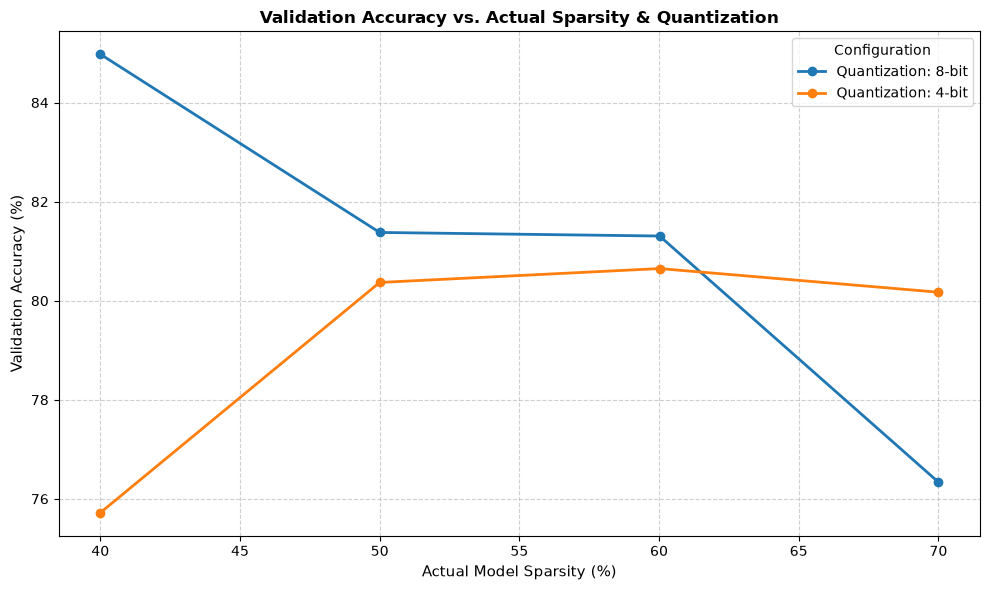

In [66]:
# Plot results
plot_results(results, QUANTIZATIONS)

In [67]:
def load_best_hps(best_hps_path):
  """Load the best Hyperparameters."""

  print(f"[+] Loading best Hyperparameters from: '{best_hps_path}'...")

  # Load the best Hyperparameters 
  with open(best_hps_path, "r") as file:
    best_hps = json.load(file)

  print("[+] Best Hyperparameters successfully loaded!")

  return best_hps


def load_best_model(best_hps, best_model_name, best_bit_width):
  """Load the best Model."""

  print(f"[+] Loading Model from '{best_model_name}'...")

  # Extract best Hyperparameters
  conv1_filters=best_hps.get("conv1_filters")
  conv2_filters=best_hps.get("conv2_filters")
  dense_units=best_hps.get("dense_units")

  # Build the Model
  best_model = build_model(
    conv1_filters,
    conv2_filters,
    dense_units,
    input_shape,
    num_classes,
    bit_width=best_bit_width
  )
  best_model.to(device)

  # Load the Model
  best_model.load_state_dict(torch.load(best_model_name))

  print(f"[+] Model successfully loaded!")

  return best_model


def test_model(model, ds_test):
  """Evaluate the Model on the Test Set."""

  print("[+] Testing the Model on the Test Set...")

  # Evaluate the Model
  model.eval()
  test_loss = 0.0
  correct = 0
  total = 0
  with torch.no_grad():
    for images, labels in ds_test:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      batch_loss = torch.nn.functional.cross_entropy(outputs, labels)
      test_loss += batch_loss.item() * images.size(0)
      _, predicted = torch.max(outputs.data, dim=1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()
  test_loss = test_loss / total
  test_accuracy = correct / total

  print("[+] Model successfully tested!")

  print("[+] Printing Test Metrics...")

  print(f"[+] Test Loss: {test_loss}")
  print(f"[+] Test Accuracy: {test_accuracy}")

  return test_loss, test_accuracy

In [68]:
# Define best Hyperparameters path
best_hps_path = "best_hyperparameters.json"
best_hps_path = os.path.join(current_dir, best_hps_path)

# Load the best Hyperparameters
best_hps = load_best_hps(best_hps_path)

# Define best Quantization and target Sparsity
BEST_Q_NAME = "8-bit"
BEST_BIT_WIDTH = 8
BEST_TARGET_SPARSITY = 0.4

# Define best Model Name
best_model_name = f"pynq_zu_model_{BEST_Q_NAME}_sparsity{int(BEST_TARGET_SPARSITY*100)}.pth"
best_model_name = os.path.join(current_dir, best_model_name)

# Load the best Model
best_model = load_best_model(
  best_hps,
  best_model_name,
  BEST_BIT_WIDTH
)

# Test the best Model 
test_loss, test_accuracy = test_model(best_model, ds_test)

[+] Loading best Hyperparameters from: '/home/sky/projects/hls4ml_pynq_zu_emnist/best_hyperparameters.json'...
[+] Best Hyperparameters successfully loaded!
[+] Loading Model from '/home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity40.pth'...
[+] Building CNN Model...
[+] CNN Model successfully built!
[+] Model successfully loaded!
[+] Testing the Model on the Test Set...
[+] Model successfully tested!
[+] Printing Test Metrics...
[+] Test Loss: 0.48510149588951695
[+] Test Accuracy: 0.8507692307692307


In [69]:
import qonnx
import qonnx.core.modelwrapper
import qonnx.util.cleanup
import qonnx.transformation.channels_last
import qonnx.transformation.gemm_to_matmul
import brevitas.export


def export_to_qonnx(model, qonnx_path, input_shape):
  """Export Model to QONNX format."""

  print("[+] Exporting model to QONNX...")

  # Export to QONNX format
  model.eval()
  dummy_input = torch.randn(1, *input_shape).to(device)
  brevitas.export.export_qonnx(model, dummy_input, qonnx_path)

  print(f"[+] QONNX model successfully exported to: {qonnx_path}!")


def clean_qonnx(qonnx_path, cleaned_qonnx_path):
  """Clean the QONNX Model."""

  print("[+] Loading QONNX Model...")

  # Load QONNX Model
  qonnx_model = qonnx.core.modelwrapper.ModelWrapper(qonnx_path)

  print("[+] QONNX Model successfully loaded!")

  print("[+] Performing clean up...")

  # Perform general clean up
  qonnx_model = qonnx.util.cleanup.cleanup_model(qonnx_model)

  # Convert to channels-last convention
  qonnx_model = qonnx_model.transform(qonnx.transformation.channels_last.ConvertToChannelsLastAndClean())

  # Convert GEMM to MatMul
  qonnx_model = qonnx_model.transform(qonnx.transformation.gemm_to_matmul.GemmToMatMul())

  # Perform final clean up
  qonnx_model = qonnx.util.cleanup.cleanup_model(qonnx_model)

  print("[+] Clean up successfully performed!")

  # Save cleaned Model
  qonnx_model.save(cleaned_qonnx_path)

  print(f"[+] Cleaned QONNX Model saved to: '{cleaned_qonnx_path}'!")

  return qonnx_model

In [70]:
# Define QONNX path
qonnx_path = f"pynq_zu_model_{BEST_Q_NAME}_sparsity{int(BEST_TARGET_SPARSITY*100)}.onnx"
qonnx_path = os.path.join(current_dir, qonnx_path)

# Export the best Model to QONNX format
export_to_qonnx(
  best_model,
  qonnx_path,
  input_shape
)

# Define cleaned QONNX path
cleaned_qonnx_path = f"pynq_zu_model_{BEST_Q_NAME}_sparsity{int(BEST_TARGET_SPARSITY*100)}_cleaned.onnx"
cleaned_qonnx_path = os.path.join(current_dir, cleaned_qonnx_path)

# Clean QONNX
qonnx_model = clean_qonnx(qonnx_path, cleaned_qonnx_path)

[+] Exporting model to QONNX...
[torch.onnx] Obtain model graph for `QuantizedCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `QuantizedCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[+] QONNX model successfully exported to: /home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity40.onnx!
[+] Loading QONNX Model...
[+] QONNX Model successfully loaded!
[+] Performing clean up...


/home/sky/projects/hls4ml_pynq_zu_emnist/.venv/lib/python3.12/site-packages/qonnx/transformation/gemm_to_matmul.py:57: UserWarning: The GemmToMatMul transformation only offers explicit support for version 9 of the Gemm node, but the ONNX version of the supplied model is 2. Thus the transformation may fail or return incomplete results.
  warnings.warn(


[+] Clean up successfully performed!
[+] Cleaned QONNX Model saved to: '/home/sky/projects/hls4ml_pynq_zu_emnist/pynq_zu_model_8-bit_sparsity40_cleaned.onnx'!


In [71]:
import hls4ml


def build_hls_latency(qonnx_model, output_dir, project_name, backend, part, clock_period, io_type):
  """Build and compile the hls4ml Model using the Latency Strategy."""

  print("[+] Building and compiling HLS Model using the Latency Strategy...")

  # Generate HLS config
  hls_config = hls4ml.utils.config_from_onnx_model(
    model=qonnx_model,
    granularity="name",
    backend=backend
  )
  hls_config["Model"]["Strategy"] = "Latency"
  hls_config["Model"]["ReuseFactor"] = 1

  print("Printing HLS Config...")
  print(hls_config)

  # Convert to HLS Model
  hls_model = hls4ml.converters.convert_from_onnx_model(
    model=qonnx_model,
    output_dir=output_dir,
    project_name=project_name,
    hls_config=hls_config,
    backend=backend,
    part=part,
    clock_period=clock_period,
    io_type=io_type
  )

  # Compile the HLS Model
  hls_model.compile()

  print("[+] HLS Model using the Latency Strategy successfully built and compiled!")

  return hls_model


def build_hls_resource(qonnx_model, output_dir, project_name, backend, part, clock_period, io_type, reuse_factor):
  """Build and compile the hls4ml Model using the Resource Strategy."""

  print("[+] Building and compiling HLS Model using the Resource Strategy...")

  # Generate HLS config
  hls_config = hls4ml.utils.config_from_onnx_model(
    model=qonnx_model,
    granularity="name",
    backend=backend
  )
  hls_config["Model"]["Strategy"] = "Resource"
  hls_config["Model"]["ReuseFactor"] = reuse_factor 

  print("Printing HLS Config...")
  print(hls_config)

  # Convert from ONNX
  hls_model = hls4ml.converters.convert_from_onnx_model(
    model=qonnx_model,
    output_dir=output_dir,
    project_name=project_name,
    hls_config=hls_config,
    backend=backend,
    part=part,
    clock_period=clock_period,
    io_type=io_type
  )

  # Compile
  hls_model.compile()

  print("[+] HLS Model using the Resource Strategy successfully built and compiled!")

  return hls_model


def build_hls_da(qonnx_model, output_dir, project_name, backend, part, clock_period, io_type):
  """Build and compile the hls4ml Model using the Distributed Arithmetic Strategy."""

  print("[+] Building and compiling HLS Model using the Distributed Arithmetic Strategy...")

  # Generate HLS config
  hls_config = hls4ml.utils.config_from_onnx_model(
    model=qonnx_model,
    granularity="name",
    backend=backend
  )
  hls_config["Model"]["Strategy"] = "da"
  hls_config["Model"]["ReuseFactor"] = 1 

  print("Printing HLS Config...")
  print(hls_config)

  # Convert from ONNX
  hls_model = hls4ml.converters.convert_from_onnx_model(
    model=qonnx_model,
    output_dir=output_dir,
    project_name=project_name,
    hls_config=hls_config,
    backend=backend,
    part=part,
    clock_period=clock_period,
    io_type=io_type
  )

  # Compile
  hls_model.compile()

  print("[+] HLS Model using the Distributed Arithmetic Strategy successfully built and compiled!")

  return hls_model


def test_hls_model(hls_model, original_model, device, ds_test, num_samples):
  """Test the compiled hls4ml Model against the original Model."""

  print("[+] Testing HLS Model...")

  # Prepare original Model for Evaluation
  original_model.eval()
  original_model.to(device)

  # Testing Metrics
  hls_preds = []
  original_preds = []  
  true_labels = []

  # Evaluate Models
  collected = 0
  with torch.no_grad():
    for images, labels in ds_test:
      # Evaluate only on the specified number of samples
      if collected >= num_samples:
        break

      # Compute sample subset
      batch_size = images.size(0)
      take = min(batch_size, num_samples - collected)
      img_cpu = images[:take]
      lbl_subset = labels[:take]

      # Evaluate orignal Model 
      img_gpu = img_cpu.to(device)
      original_output = original_model(img_gpu)

      # Evaluate HLS Model (transpose data channels-last convention)
      np_img = img_cpu.numpy()
      if np_img.ndim == 4 and np_img.shape[1] == 1:  
          np_img_nhwc = np.transpose(np_img, (0, 2, 3, 1))
      else:
          np_img_nhwc = np_img
      hls_output = hls_model.predict(np_img_nhwc)

      # Store predictions
      hls_preds.append(np.argmax(hls_output, axis=1))
      original_preds.append(original_output.detach().cpu().argmax(dim=1).numpy())
      true_labels.append(lbl_subset.numpy())

      # Update number of evaluated samples 
      collected += take

  # Concatenate results 
  hls_preds = np.concatenate(hls_preds)
  original_preds = np.concatenate(original_preds)
  true_labels = np.concatenate(true_labels)

  # Compute Metrics
  hls_accuracy = np.mean(hls_preds == true_labels)
  original_accuracy = np.mean(original_preds == true_labels)
  agreement = np.mean(hls_preds == original_preds)

  print("[+] HLS Model successfully tested!")

  print("[+] Printing HLS Model Testing results...")

  # Print results
  print(f"[+] Original Model Accuracy: {original_accuracy}")
  print(f"[+] HLS Model Accuracy:  {hls_accuracy}")
  print(f"[+] Prediction Agreement: {agreement}")

  return hls_preds, hls_accuracy


def save_hls_model(hls_model, hls_model_name):
  """Save HLS Model and write Project Files in the Output Directory."""

  print("[+] Saving HLS Model...")

  # Save HLS Model
  hls_model.save(hls_model_name)

  print(f"[+] HLS Model successfully saved to: '{hls_model_name}'!")

  print("[+] Writing Project Files...")

  # Write Project Files
  hls_model.write()

  print(f"[+] Project Files successfully wrote to: '{hls_model.config.get_output_dir()}'!")

In [72]:
# Define Project Name, Vitis Backend and PYNQ-ZU Part
PROJECT_NAME = "PYNQ_ZU_EMNIST"
VITIS_BACKEND = "Vitis"
PYNQ_ZU_PART="xczu5eg-sfvc784-1-e"

# Define Ouput Directories
latency_dir = "HLS_latency"
latency_dir = os.path.join(current_dir, latency_dir)
resource_dir = "HLS_resource"
resource_dir = os.path.join(current_dir, resource_dir)
da_dir = "HLS_da"
da_dir = os.path.join(current_dir, da_dir)

# Define Model Names
latency_model_name = f"pynq_zu_model_{BEST_Q_NAME}_sparsity{int(BEST_TARGET_SPARSITY*100)}_latency.fml"
latency_model_name = os.path.join(current_dir, latency_model_name)
resource_model_name = f"pynq_zu_model_{BEST_Q_NAME}_sparsity{int(BEST_TARGET_SPARSITY*100)}_resource.fml"
resource_model_name = os.path.join(current_dir, resource_model_name)
da_model_name = f"pynq_zu_model_{BEST_Q_NAME}_sparsity{int(BEST_TARGET_SPARSITY*100)}_da.fml"
da_model_name = os.path.join(current_dir, da_model_name)

In [73]:
# Build, test and save the Latency Strategy HLS Model
hls_latency_model = build_hls_latency(
  qonnx_model,
  latency_dir,
  PROJECT_NAME,
  VITIS_BACKEND,
  PYNQ_ZU_PART,
  clock_period=5,
  io_type="io_parallel"
)
test_hls_model(
  hls_latency_model, 
  best_model, 
  device, 
  ds_test, 
  num_samples=256
)
save_hls_model(hls_latency_model, latency_model_name)

[+] Building and compiling HLS Model using the Latency Strategy...
Output layers:  ['Add_1']
Input shape: [1, 28, 28]
Topology:
Layer name: Quant_0, layer type: Quant, current shape: [[8, 3, 3, 1]]
Layer name: Quant_1, layer type: Quant, current shape: [[8]]
Layer name: Quant_2, layer type: Quant, current shape: [[4, 3, 3, 8]]
Layer name: Quant_3, layer type: Quant, current shape: [[4]]
Layer name: Quant_4, layer type: Quant, current shape: [[196, 16]]
Layer name: Quant_5, layer type: Quant, current shape: [[16]]
Layer name: Quant_6, layer type: Quant, current shape: [[16, 26]]
Layer name: Quant_7, layer type: Quant, current shape: [[26]]
Layer name: Transpose_0, layer type: Transpose, current shape: [[1, 1, 28, 28]]
Layer name: Quant_8, layer type: Quant, current shape: [[1, 28, 28, 1]]
Layer name: Conv_0, layer type: Conv, current shape: [[1, 28, 28, 1], [8, 3, 3, 1], [8]]
Layer name: Relu_0, layer type: Activation, current shape: [[1, 28, 28, 8]]
Layer name: Quant_9, layer type: Qua

In [74]:
# Build, test and save the Resource Strategy HLS Model
hls_resource_model = build_hls_resource(
  qonnx_model,
  resource_dir,
  PROJECT_NAME,
  VITIS_BACKEND,
  PYNQ_ZU_PART,
  clock_period=5,
  io_type="io_stream",
  reuse_factor=2
)
test_hls_model(
  hls_resource_model, 
  best_model, 
  device, 
  ds_test, 
  num_samples=256
)
save_hls_model(hls_resource_model, resource_model_name)

[+] Building and compiling HLS Model using the Resource Strategy...
Output layers:  ['Add_1']
Input shape: [1, 28, 28]
Topology:
Layer name: Quant_0, layer type: Quant, current shape: [[8, 3, 3, 1]]
Layer name: Quant_1, layer type: Quant, current shape: [[8]]
Layer name: Quant_2, layer type: Quant, current shape: [[4, 3, 3, 8]]
Layer name: Quant_3, layer type: Quant, current shape: [[4]]
Layer name: Quant_4, layer type: Quant, current shape: [[196, 16]]
Layer name: Quant_5, layer type: Quant, current shape: [[16]]
Layer name: Quant_6, layer type: Quant, current shape: [[16, 26]]
Layer name: Quant_7, layer type: Quant, current shape: [[26]]
Layer name: Transpose_0, layer type: Transpose, current shape: [[1, 1, 28, 28]]
Layer name: Quant_8, layer type: Quant, current shape: [[1, 28, 28, 1]]
Layer name: Conv_0, layer type: Conv, current shape: [[1, 28, 28, 1], [8, 3, 3, 1], [8]]
Layer name: Relu_0, layer type: Activation, current shape: [[1, 28, 28, 8]]
Layer name: Quant_9, layer type: Qu

In [75]:
# NOTE: Skip Distributed Arithmetic Strategy because of unsupported Activation Layer
# Build, test and save the Distributed Arithmetic HLS Model
# hls_da_model = build_hls_da(
#   qonnx_model,
#   da_dir,
#   PROJECT_NAME,
#   VITIS_BACKEND,
#   PYNQ_ZU_PART,
#   clock_period=5,
#   io_type="io_parallel",
# )
# test_hls_model(
#   hls_da_model, 
#   best_model, 
#   device, 
#   ds_test, 
#   num_samples=256
# )
# save_hls_model(hls_da_model, da_model_name)

In [2]:
import os
import subprocess
import hls4ml
import hls4ml.converters


def source_vitis_env(settings_file):
  """Source the Vitis settings script and inject Environment Variables into os.environ."""

  print(f"[+] Sourcing Vitis environment from: {settings_file}...")

  cmd = f"source {settings_file} && env"
  proc = subprocess.Popen(["bash", "-c", cmd], stdout=subprocess.PIPE)
  for line in proc.stdout:
    line_str = line.decode("utf-8").strip()
    key, _, value = line_str.partition("=")
    if key and value:
      os.environ[key] = value

  print("[+] Vitis environment successfully loaded!")


def link_hls_project(project_dir):
  """Link to an existing hls4ml project directory."""

  print(f"[+] Linking to existing HLS project directory: '{project_dir}'...")

  # Link the existing Project Directory
  linked_model = hls4ml.converters.link_existing_project(project_dir)

  print("[+] HLS Project successfully linked!")

  return linked_model


def load_hls_saved_model(hls_model_name):
  """Load a saved hls4ml model (.fml archive)."""
  print(f"[+] Loading saved HLS model from: '{hls_model_name}'...")

  # Load saved Model 
  loaded_model = hls4ml.converters.load_saved_model(hls_model_name)

  print("[+] Saved HLS model successfully loaded!")

  return loaded_model

In [3]:
# Target the Vitis settings script to expose 'vitis-run' on PATH
source_vitis_env("/tools/Xilinx/Vitis/2024.1/settings64.sh")

# Define current Directory
current_dir = os.getcwd()

# Define Project Directories
latency_dir = "HLS_latency"
latency_dir = os.path.join(current_dir, latency_dir)
resource_dir = "HLS_resource"
resource_dir = os.path.join(current_dir, resource_dir)

# Define Model names
latency_model_name = "pynq_zu_model_8-bit_sparsity40_latency.fml"
resource_model_name = "pynq_zu_model_8-bit_sparsity40_resource.fml"

# Load the HLS Models
hls_latency_model = load_hls_saved_model(latency_model_name)
hls_resource_model = load_hls_saved_model(resource_model_name)

[+] Sourcing Vitis environment from: /tools/Xilinx/Vitis/2024.1/settings64.sh...
[+] Vitis environment successfully loaded!
[+] Loading saved HLS model from: 'pynq_zu_model_8-bit_sparsity40_latency.fml'...
[+] Saved HLS model successfully loaded!
[+] Loading saved HLS model from: 'pynq_zu_model_8-bit_sparsity40_resource.fml'...
[+] Saved HLS model successfully loaded!


In [4]:
import hls4ml.report


def run_hls_synthesis(hls_model, hls_dir, csim, synth, cosim, export):
  """Compile and Synthesize the given HLS Model."""

  print("[+] Compiling HLS Model...")
  
  # Compile the HLS Model
  hls_model.compile()
  
  print("[+] HLS Model successfully compiled!")

  print("[+] Starting HLS Synthesis...")

  # Synthesize the HLS Model 
  hls_model.build(
    csim=csim, 
    synth=synth, 
    cosim=cosim, 
    export=export
  )

  print("[+] HLS Synthesis successfully completed!")

  print("[+] Printing out Report...")

  hls4ml.report.read_vivado_report(hls_dir)

In [6]:
# NOTE: Skip HLS Latency Model Synthesis because not enough resources
# Synthesize the HLS Latency Model
# run_hls_synthesis(
#   hls_latency_model,
#   latency_dir,
#   csim=False,  
#   synth=True,  
#   cosim=False, 
#   export=True  
# )

In [5]:
# Synthesize the HLS Resource Model
run_hls_synthesis(
  hls_resource_model,
  resource_dir,
  csim=False,  
  synth=True,  
  cosim=False, 
  export=True  
)

[+] Compiling HLS Model...
[+] HLS Model successfully compiled!
[+] Starting HLS Synthesis...

****** vitis-run v2024.1 (64-bit)
  **** SW Build 5074859 on 2024-05-20-23:21:20
  **** Start of session at: Sun Nov  8 18:11:41 2026
    ** Copyright 1986-2022 Xilinx, Inc. All Rights Reserved.
    ** Copyright 2022-2024 Advanced Micro Devices, Inc. All Rights Reserved.

INFO: [vitis-run 82-31] Launching vitis_hls: vitis_hls -nolog -run tcl -f /home/sky/projects/hls4ml_pynq_zu_emnist/HLS_resource/build_prj.tcl -work_dir /home/sky/projects/hls4ml_pynq_zu_emnist/HLS_resource

****** Vitis HLS - High-Level Synthesis from C, C++ and OpenCL v2024.1 (64-bit)
  **** SW Build 5069499 on May 21 2024
  **** IP Build 5075265 on Wed May 22 21:45:21 MDT 2024
  **** SharedData Build 5076995 on Wed May 22 18:29:18 MDT 2024
  **** Start of session at: Sun Nov  8 18:11:42 2026
    ** Copyright 1986-2022 Xilinx, Inc. All Rights Reserved.
    ** Copyright 2022-2024 Advanced Micro Devices, Inc. All Rights Reser